# Analysis of reliability on raw observer responses

In [1]:
import warnings
from pathlib import Path
import random

import pandas as pd
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from load_data import load_all, DATA_ROOT
from greeble_views import same_individual_rate
from helper_functions_raw_responses import get_inter_intra_dataframe_per_observer, get_response_matrix_all, get_observer_responses_per_rep, create_random_pooling, pairwise_agreement_with_pooled, pairwise_agreement, check_runs_pairwise, clean_triplet_indices, get_observer_responses_per_rep

warnings.simplefilter(action='ignore', category=FutureWarning)
sns.set_style('whitegrid')
sns.set_context("notebook")

palette_imset = {'action': (0.4, 0.7607843137254902, 0.6470588235294118),
                 'greebles': (0.9882352941176471, 0.5529411764705883, 0.3843137254901961),
                 'taxonomic': (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
                }
palette_task = {'classic': (0.190631, 0.407061, 0.556089),
                'odd one out': (0.20803, 0.718701, 0.472873),
               }


plot_dir = Path('../plots/Comparisong_Intra_vs_Inter')
plot_dir.mkdir(parents=True, exist_ok=True)

# seeds the jitter of the strip plots (seaborn draws it from numpy's global generator) and of Figure S5
SEED = 0


In [2]:
## Loading data and replacing P1 with O5 for easier handling

In [3]:
# load all data 
df = load_all()

In [4]:
# This bit of code is dealing with the fact, that P1 == O1 
# ...and P1 has the first repetitions and O5 repetitions 2 & 3: 

temp = df[(df['observer'] == 'P1') & (df['session'].isin(['1a', '1b', '2b', '2a']))]

# Change 'observer' to 'O5' in temp
temp['observer'] = 'O5'

# Concatenate df and temp
df = pd.concat([df, temp], ignore_index=True)


/tmp/ipykernel_875008/1350154310.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp['observer'] = 'O5'


## Computing the percentage of identical choices for each pair of observers and compare with intra-observer reliability

In [5]:
tasks          = ['classic', 'odd one out']
image_sets     = ['taxonomic', 'action', 'greebles']
obs_names      = ['O1', 'O2', 'O3', 'O4', 'O5'] 

In [6]:
# creating data frames which contain Inter and intra-observer reliability for all observers.
d = []
for ref_obs in obs_names:
    ref_obs_df = get_inter_intra_dataframe_per_observer(df,ref_obs, obs_names, tasks, image_sets )
    ref_obs_df['Reference Observer'] = ref_obs
    d.append(ref_obs_df)
    
df_combined = pd.concat(d, ignore_index=True)

Reference observer is:  O1
[0.8266666666666667, 0.8533333333333334] [0.7733333333333333, 0.8333333333333334] [0.8133333333333334, 0.8266666666666667]
[0.8633333333333333, 0.9] [0.84, 0.8566666666666667] [0.8233333333333334, 0.8566666666666667]
[0.8260869565217391, 0.8466666666666667] [0.802675585284281, 0.7866666666666666] [0.8160535117056856, 0.7866666666666666]
[0.8833333333333333, 0.9096989966555183] [0.8966666666666666, 0.9364548494983278] [0.88, 0.903010033444816]
[0.9333333333333333, 0.9366666666666666] [0.9066666666666666, 0.9166666666666666] [0.9233333333333333, 0.9166666666666666]
[0.83, 0.8633333333333333] [0.8466666666666667, 0.7966666666666666] [0.8666666666666667, 0.8133333333333334]


Reference observer is:  O2
[0.92, 0.9566666666666667] [0.9166666666666666, 0.93] [0.9166666666666666, 0.92]
[0.8896321070234113, 0.93] [0.8862876254180602, 0.9066666666666666] [0.8963210702341137, 0.91]
[0.8833333333333333, 0.9166666666666666] [0.86, 0.93] [0.8966666666666666, 0.9133333333333333]
[0.91, 0.9166666666666666] [0.9266666666666666, 0.92] [0.92, 0.94]
[0.8833333333333333, 0.95] [0.8766666666666667, 0.8933333333333333] [0.95, 0.87]
[0.9333333333333333, 0.9733333333333334] [0.9633333333333334, 0.9633333333333334] [0.95, 0.9633333333333334]


Reference observer is:  O3
[0.82, 0.8166666666666667] [0.84, 0.8366666666666667] [0.8133333333333334, 0.8333333333333334]
[0.77, 0.76] [0.8033333333333333, 0.79] [0.7866666666666666, 0.7766666666666666]
[0.6366666666666667, 0.5666666666666667] [0.6933333333333334, 0.7266666666666667] [0.6366666666666667, 0.5933333333333334]
[0.7833333333333333, 0.81] [0.81, 0.8233333333333334] [0.72, 0.83]
[0.68, 0.69] [0.68, 0.67] [0.68, 0.72]
[0.5133333333333333, 0.6666666666666666] [0.51, 0.5533333333333333] [0.5266666666666666, 0.5266666666666666]


Reference observer is:  O4
[0.72, 0.6722408026755853] [0.8266666666666667, 0.7123745819397993] [0.7066666666666667, 0.7324414715719063]
[0.7651006711409396, 0.82] [0.7718120805369127, 0.7633333333333333] [0.7114093959731543, 0.79]
[0.68, 0.7433333333333333] [0.6866666666666666, 0.75] [0.6466666666666666, 0.74]
[0.8523489932885906, 0.9266666666666666] [0.9093959731543624, 0.9133333333333333] [0.8523489932885906, 0.8933333333333333]
[0.82, 0.8361204013377926] [0.8666666666666667, 0.7959866220735786] [0.8266666666666667, 0.7993311036789298]
[0.7591973244147158, 0.8] [0.8695652173913043, 0.7] [0.7391304347826086, 0.7566666666666667]


Reference observer is:  O5
[0.9324324324324325, 0.9427609427609428] [0.9425675675675675, 0.9562289562289562] [0.9493243243243243, 0.9393939393939394]
[0.9395973154362416, 0.96] [0.9093959731543624, 0.9433333333333334] [0.9161073825503355, 0.9233333333333333]
[0.8430034129692833, 0.8619528619528619] [0.7337883959044369, 0.734006734006734] [0.7337883959044369, 0.7508417508417509]
[0.99, 0.9966666666666667] [0.99, 0.9933333333333333] [1, 0.99]
[0.9966555183946488, 0.9966555183946488] [0.979933110367893, 0.9665551839464883] [0.9832775919732442, 0.9698996655518395]
[0.8862876254180602, 0.92] [0.6622073578595318, 0.6533333333333333] [0.6688963210702341, 0.6666666666666666]


In [7]:
df_combined

,Agreement,Observer,Task,ImageSet,Agreement_Type,Scaled Agreement,Reference Observer
0,0.772222,O2,classic,taxonomic,Inter,0.544444,O1
1,0.778766,O2,odd one out,taxonomic,Inter,0.669800,O1
2,0.854919,O2,classic,action,Inter,0.709839,O1
3,0.907222,O2,odd one out,action,Inter,0.861526,O1
4,0.709839,O2,classic,greebles,Inter,0.419678,O1
...,...,...,...,...,...,...,...
205,0.973244,O5,odd one out,action,Intra,0.960066,O5
206,0.976589,O5,odd one out,action,Intra,0.965058,O5
207,0.903144,O5,odd one out,greebles,Intra,0.855439,O5
208,0.657770,O5,odd one out,greebles,Intra,0.489209,O5


In [8]:
# calculate mean over 3 sessions for case of intra-obs comparison, or over 4 comparisons in case of inter-obs comparison
df1 = df_combined.groupby(['Observer', 'Agreement_Type', 'Task', 'ImageSet'], as_index=False)['Agreement'].mean()
df2 = df_combined.groupby(['Observer', 'Agreement_Type', 'Task', 'ImageSet'], as_index=False)['Scaled Agreement'].mean()

df_mean = df1.merge(df2)
df_mean['Reference Observer'] = 'All observers'

In [9]:
df_combined_with_mean = pd.concat((df_combined, df_mean))

### Making tables for the paper

In [10]:
# make a df copy for transforming to percent 
df_combined_with_mean_percent = df_combined_with_mean.copy()
# tranform to percent, i.e. * 100
df_combined_with_mean_percent['Agreement'] = df_combined_with_mean_percent['Agreement'] * 100
df_combined_with_mean_percent['Scaled Agreement'] = df_combined_with_mean_percent['Scaled Agreement'] * 100

In [11]:
# group by agreement type and task, and and get mean of scaled agreement and agreement & add standard deviation for error bars:
df_grouped = df_combined_with_mean_percent.groupby(['Agreement_Type', 'Task']).agg({'Agreement': ['mean', 'std'], 'Scaled Agreement': ['mean', 'std'],}).reset_index()

# multilevel index for agreement type, image set and task:
df_grouped.set_index(['Agreement_Type', 'Task'], inplace=True)
df_grouped

Agreement            Scaled Agreement           
                                 mean        std             mean        std
Agreement_Type Task                                                         
Inter          classic      74.934436   7.062689        49.868871  14.125377
               odd one out  69.791686  13.478904        54.912965  20.117768
Intra          classic      82.178844   8.962532        64.357688  17.925065
               odd one out  84.536619  12.130005        76.920326  18.104485

In [12]:
# make into LaTeX table, restrict to 1 decimal  and print:
latex_table = df_grouped.to_latex(index=True, float_format='%.1f')
print(latex_table)

\begin{tabular}{llrrrr}
\toprule
 &  & \multicolumn{2}{r}{Agreement} & \multicolumn{2}{r}{Scaled Agreement} \\
 &  & mean & std & mean & std \\
Agreement_Type & Task &  &  &  &  \\
\midrule
\multirow[t]{2}{*}{Inter} & classic & 74.9 & 7.1 & 49.9 & 14.1 \\
 & odd one out & 69.8 & 13.5 & 54.9 & 20.1 \\
\cline{1-6}
\multirow[t]{2}{*}{Intra} & classic & 82.2 & 9.0 & 64.4 & 17.9 \\
 & odd one out & 84.5 & 12.1 & 76.9 & 18.1 \\
\cline{1-6}
\bottomrule
\end{tabular}



In [13]:
# group by agreement type and task, and and get mean of scaled agreement and agreement & add standard deviation for error bars:
df_grouped = df_combined_with_mean_percent.groupby(['Agreement_Type', 'ImageSet', 'Task']).agg({'Agreement': ['mean', 'std'], 
                                                                                        'Scaled Agreement': ['mean', 'std'],}).reset_index()

# multilevel index for agreement type, image set and task:
df_grouped.set_index(['Agreement_Type', 'ImageSet', 'Task'], inplace=True)
df_grouped

Agreement            Scaled Agreement  \
                                           mean        std             mean   
Agreement_Type ImageSet  Task                                                 
Inter          action    classic      79.790654   4.479656        59.581308   
                         odd one out  73.916283  10.101667        61.069079   
               greebles  classic      67.272508   4.343590        34.545016   
                         odd one out  57.141251  11.249525        36.031718   
               taxonomic classic      77.740145   4.577200        55.480290   
                         odd one out  78.317525   8.452560        67.638097   
Intra          action    classic      84.863323   6.714732        69.726646   
                         odd one out  86.381382  10.502775        79.673705   
               greebles  classic      76.740659   9.520049        53.481317   
                         odd one out  77.139836  14.477512        65.880353   
               taxonomic classic      84.932550   8.186537        69.865100   
                         odd one out  90.088637   6.585669        85.206921   

                                                 
                                            std  
Agreement_Type ImageSet  Task                    
Inter          action    classic       8.959312  
                         odd one out  15.077115  
               greebles  classic       8.687180  
                         odd one out  16.790336  
               taxonomic classic       9.154400  
                         odd one out  12.615761  
Intra          action    classic      13.429465  
                         odd one out  15.675783  
               greebles  classic      19.040097  
                         odd one out  21.608226  
               taxonomic classic      16.373074  
                         odd one out   9.829357

In [14]:
# make into LaTeX table, restrict to 1 decimal  and print:
latex_table = df_grouped.to_latex(index=True, float_format='%.1f')
print(latex_table)

\begin{tabular}{lllrrrr}
\toprule
 &  &  & \multicolumn{2}{r}{Agreement} & \multicolumn{2}{r}{Scaled Agreement} \\
 &  &  & mean & std & mean & std \\
Agreement_Type & ImageSet & Task &  &  &  &  \\
\midrule
\multirow[t]{6}{*}{Inter} & \multirow[t]{2}{*}{action} & classic & 79.8 & 4.5 & 59.6 & 9.0 \\
 &  & odd one out & 73.9 & 10.1 & 61.1 & 15.1 \\
\cline{2-7}
 & \multirow[t]{2}{*}{greebles} & classic & 67.3 & 4.3 & 34.5 & 8.7 \\
 &  & odd one out & 57.1 & 11.2 & 36.0 & 16.8 \\
\cline{2-7}
 & \multirow[t]{2}{*}{taxonomic} & classic & 77.7 & 4.6 & 55.5 & 9.2 \\
 &  & odd one out & 78.3 & 8.5 & 67.6 & 12.6 \\
\cline{1-7} \cline{2-7}
\multirow[t]{6}{*}{Intra} & \multirow[t]{2}{*}{action} & classic & 84.9 & 6.7 & 69.7 & 13.4 \\
 &  & odd one out & 86.4 & 10.5 & 79.7 & 15.7 \\
\cline{2-7}
 & \multirow[t]{2}{*}{greebles} & classic & 76.7 & 9.5 & 53.5 & 19.0 \\
 &  & odd one out & 77.1 & 14.5 & 65.9 & 21.6 \\
\cline{2-7}
 & \multirow[t]{2}{*}{taxonomic} & classic & 84.9 & 8.2 & 69.9 & 16.4 \\

### Combined table: reliability per observer, image set and task

One table holding both reliability measures, for export to LaTeX, built like the dimensionality
table in `reads-and-prints-dimensionalities.ipynb`. Rows are grouped into an intra-observer and
an inter-observer block, each listing observers O1 - O5 followed by their average. Columns are
split by image set and then by task, with the average across image sets as the last image-set
block.

Each cell reads `reliability (scaled reliability)`, both in percent. The per-observer values are
the mean over the three sessions (intra-observer) or over the four pairwise comparisons
(inter-observer), that is the rows labelled `All observers` in `df_combined_with_mean_percent`.

In [15]:
OBSERVERS = ['O1', 'O2', 'O3', 'O4', 'O5']
AVERAGE_OBSERVER_LABEL = 'Average'
MEAN_IMAGE_SET_LABEL = 'mean'
AGREEMENT_TYPES = ['Intra', 'Inter']
RELIABILITY_TASKS = ['classic', 'odd one out']
RELIABILITY_IMAGE_SETS = ['action', 'greebles', 'taxonomic']
RELIABILITY_MEASURES = ['Agreement', 'Scaled Agreement']


def reliability_summary_table(dataframe):
    """Reliability and scaled reliability in one numeric table.

    Rows: (agreement type, observer), with the average over O1 - O5 after the individual
    observers. Columns: (image set, task, measure), with an extra 'mean' image set
    averaging across the three image sets.
    """
    # the 'All observers' rows already hold one value per observer, task and image set,
    # averaged over sessions (intra) or over pairwise comparisons (inter)
    long = dataframe[dataframe['Reference Observer'] == 'All observers'].copy()
    long = long[['Observer', 'Agreement_Type', 'Task', 'ImageSet'] + RELIABILITY_MEASURES]

    # average across image sets, added as an extra image set
    across_imagesets = long.groupby(
        ['Observer', 'Agreement_Type', 'Task'], as_index=False)[RELIABILITY_MEASURES].mean()
    across_imagesets['ImageSet'] = MEAN_IMAGE_SET_LABEL
    long = pd.concat([long, across_imagesets], ignore_index=True)

    # average across observers, added as an extra observer
    across_observers = long.groupby(
        ['Agreement_Type', 'Task', 'ImageSet'], as_index=False)[RELIABILITY_MEASURES].mean()
    across_observers['Observer'] = AVERAGE_OBSERVER_LABEL
    long = pd.concat([long, across_observers], ignore_index=True)

    table = long.pivot_table(index=['Agreement_Type', 'Observer'],
                             columns=['ImageSet', 'Task'], values=RELIABILITY_MEASURES)
    table = table.reorder_levels(['ImageSet', 'Task', None], axis=1)
    table = table.reindex(columns=pd.MultiIndex.from_product(
        [RELIABILITY_IMAGE_SETS + [MEAN_IMAGE_SET_LABEL], RELIABILITY_TASKS, RELIABILITY_MEASURES]))
    table = table.reindex(index=pd.MultiIndex.from_product(
        [AGREEMENT_TYPES, OBSERVERS + [AVERAGE_OBSERVER_LABEL]]))
    table.columns.names = ['ImageSet', 'Task', 'measure']
    table.index.names = ['Agreement_Type', 'Observer']
    return table


def format_reliability_table(table):
    """Collapse the two measures into one 'reliability (scaled reliability)' column per cell."""
    columns = pd.MultiIndex.from_product(
        [RELIABILITY_IMAGE_SETS + [MEAN_IMAGE_SET_LABEL], RELIABILITY_TASKS],
        names=['ImageSet', 'Task'])
    formatted = pd.DataFrame(index=table.index, columns=columns, dtype=object)

    for image_set in RELIABILITY_IMAGE_SETS + [MEAN_IMAGE_SET_LABEL]:
        for task in RELIABILITY_TASKS:
            reliability = table[(image_set, task, 'Agreement')]
            scaled = table[(image_set, task, 'Scaled Agreement')]
            formatted[(image_set, task)] = (reliability.map('{:.1f}'.format)
                                            + ' (' + scaled.map('{:.1f}'.format) + ')')
    return formatted


reliability_summary = reliability_summary_table(df_combined_with_mean_percent)
reliability_summary.round(1)

ImageSet                   action                               \
Task                      classic                  odd one out   
measure                 Agreement Scaled Agreement   Agreement   
Agreement_Type Observer                                          
Intra          O1            85.7             71.3        92.2   
               O2            90.3             80.6        90.4   
               O3            78.1             56.2        68.7   
               O4            77.0             54.1        82.4   
               O5            93.2             86.4        98.2   
               Average       84.9             69.7        86.4   
Inter          O1            81.2             62.5        79.2   
               O2            82.4             64.8        79.5   
               O3            76.4             52.8        64.8   
               O4            76.5             53.0        68.9   
               O5            82.4             64.7        77.2   
               Average       79.8             59.6        73.9   

ImageSet                                  greebles                   \
Task                                       classic                    
measure                 Scaled Agreement Agreement Scaled Agreement   
Agreement_Type Observer                                               
Intra          O1                   88.4      81.1             62.2   
               O2                   85.7      90.0             80.0   
               O3                   53.2      64.2             28.4   
               O4                   73.8      70.8             41.6   
               O5                   97.3      77.6             55.2   
               Average              79.7      76.7             53.5   
Inter          O1                   69.0      66.4             32.8   
               O2                   69.3      71.3             42.7   
               O3                   47.5      64.5             29.0   
               O4                   53.6      69.4             38.7   
               O5                   65.9      64.8             29.6   
               Average              61.1      67.3             34.5   

ImageSet                                             taxonomic  \
Task                    odd one out                    classic   
measure                   Agreement Scaled Agreement Agreement   
Agreement_Type Observer                                          
Intra          O1              83.6             75.5      82.1   
               O2              95.8             93.7      92.7   
               O3              54.9             32.8      82.7   
               O4              77.1             65.8      72.8   
               O5              74.3             61.6      94.4   
               Average         77.1             65.9      84.9   
Inter          O1              54.8             32.5      75.4   
               O2              65.8             48.9      81.0   
               O3              54.5             32.1      78.4   
               O4              63.8             45.9      74.5   
               O5              46.9             20.7      79.4   
               Average         57.1             36.0      77.7   

ImageSet                                                               \
Task                                     odd one out                    
measure                 Scaled Agreement   Agreement Scaled Agreement   
Agreement_Type Observer                                                 
Intra          O1                   64.2        90.2             85.3   
               O2                   85.3        92.2             88.4   
               O3                   65.3        79.6             69.6   
               O4                   45.7        89.1             83.8   
               O5                   88.8        99.3             99.0   
               Average              69.9        90.1             85.2   
Inter          O1  

In [16]:
reliability_formatted = format_reliability_table(reliability_summary)
reliability_formatted

ImageSet                      action                  greebles               \
Task                         classic  odd one out      classic  odd one out   
Agreement_Type Observer                                                       
Intra          O1        85.7 (71.3)  92.2 (88.4)  81.1 (62.2)  83.6 (75.5)   
               O2        90.3 (80.6)  90.4 (85.7)  90.0 (80.0)  95.8 (93.7)   
               O3        78.1 (56.2)  68.7 (53.2)  64.2 (28.4)  54.9 (32.8)   
               O4        77.0 (54.1)  82.4 (73.8)  70.8 (41.6)  77.1 (65.8)   
               O5        93.2 (86.4)  98.2 (97.3)  77.6 (55.2)  74.3 (61.6)   
               Average   84.9 (69.7)  86.4 (79.7)  76.7 (53.5)  77.1 (65.9)   
Inter          O1        81.2 (62.5)  79.2 (69.0)  66.4 (32.8)  54.8 (32.5)   
               O2        82.4 (64.8)  79.5 (69.3)  71.3 (42.7)  65.8 (48.9)   
               O3        76.4 (52.8)  64.8 (47.5)  64.5 (29.0)  54.5 (32.1)   
               O4        76.5 (53.0)  68.9 (53.6)  69.4 (38.7)  63.8 (45.9)   
               O5        82.4 (64.7)  77.2 (65.9)  64.8 (29.6)  46.9 (20.7)   
               Average   79.8 (59.6)  73.9 (61.1)  67.3 (34.5)  57.1 (36.0)   

ImageSet                   taxonomic                      mean               
Task                         classic  odd one out      classic  odd one out  
Agreement_Type Observer                                                      
Intra          O1        82.1 (64.2)  90.2 (85.3)  83.0 (65.9)  88.7 (83.1)  
               O2        92.7 (85.3)  92.2 (88.4)  91.0 (82.0)  92.8 (89.2)  
               O3        82.7 (65.3)  79.6 (69.6)  75.0 (50.0)  67.7 (51.9)  
               O4        72.8 (45.7)  89.1 (83.8)  73.5 (47.1)  82.9 (74.4)  
               O5        94.4 (88.8)  99.3 (99.0)  88.4 (76.8)  90.6 (86.0)  
               Average   84.9 (69.9)  90.1 (85.2)  82.2 (64.4)  84.5 (76.9)  
Inter          O1        75.4 (50.8)  69.1 (53.9)  74.3 (48.7)  67.7 (51.8)  
               O2        81.0 (61.9)  81.4 (72.2)  78.2 (56.5)  75.5 (63.5)  
               O3        78.4 (56.9)  79.6 (69.6)  73.1 (46.2)  66.3 (49.7)  
               O4        74.5 (49.0)  79.9 (70.0)  73.5 (46.9)  70.9 (56.5)  
               O5        79.4 (58.8)  81.6 (72.6)  75.5 (51.0)  68.6 (53.1)  
               Average   77.7 (55.5)  78.3 (67.6)  74.9 (49.9)  69.8 (54.9)

In [17]:
DISPLAY_IMAGE_SETS = {'action': 'Action', 'greebles': 'Greebles',
                      'taxonomic': 'Taxonomic', 'mean': 'Mean'}
DISPLAY_TASKS = {'classic': 'Classic', 'odd one out': 'Odd-one-out'}
DISPLAY_AGREEMENT_TYPES = {'Intra': 'Intra-observer', 'Inter': 'Inter-observer'}

# observers whose row is preceded by a rule separating them from the individual observers
RULED_OBSERVERS = [AVERAGE_OBSERVER_LABEL]


def reliability_table_to_latex(formatted, caption, label):
    """Write the formatted table as LaTeX, grouped into intra- and inter-observer blocks.

    Same structure as the dimensionality table: two index columns (reliability type,
    observer), image sets as the outer column group with tasks nested inside, and
    \\multirow blocks per reliability type.
    """
    image_sets = list(dict.fromkeys(level for level, _ in formatted.columns))
    n_columns = 2 + formatted.shape[1]
    indent = ' ' * 4

    # group header, one \multicolumn per image set, plus the rules underneath it
    group_header = ' & '.join(
        [' ', ' '] + [f'\\multicolumn{{{len(RELIABILITY_TASKS)}}}{{c}}'
                      f'{{{DISPLAY_IMAGE_SETS[image_set]}}}' for image_set in image_sets])
    group_rules = ' '.join(
        f'\\cmidrule(lr){{{3 + len(RELIABILITY_TASKS) * position}'
        f'-{2 + len(RELIABILITY_TASKS) * (position + 1)}}}'
        for position in range(len(image_sets)))
    task_header = ' & '.join(
        [' ', ' '] + [f'\\makecell{{{DISPLAY_TASKS[task]}}}'
                      for _ in image_sets for task in RELIABILITY_TASKS])

    lines = [
        '\\begin{table}[h!]',
        indent + '\\centering',
        indent + f'\\begin{{tabular}}{{ll{"r" * formatted.shape[1]}}}',
        indent + '\\toprule',
        indent + group_header + ' \\\\',
        indent + group_rules,
        indent + task_header + ' \\\\',
        indent + 'Reliability & Observer' + ' &' * formatted.shape[1] + ' \\\\',
        indent + '\\midrule',
    ]

    for block_position, agreement_type in enumerate(AGREEMENT_TYPES):
        observers = formatted.loc[agreement_type].index.tolist()
        if block_position > 0:
            lines.append(indent + '\\noalign{\\vskip 3pt}'
                         f'\\cline{{1-{n_columns}}}\\noalign{{\\vskip 3pt}}')
        for row_position, observer in enumerate(observers):
            if observer in RULED_OBSERVERS:
                lines.append(indent + f'\\cmidrule(lr){{2-{n_columns}}}')
            first_column = (f'\\multirow[t]{{{len(observers)}}}{{*}}'
                            f'{{{DISPLAY_AGREEMENT_TYPES[agreement_type]}}}'
                            if row_position == 0 else ' ')
            values = ' & '.join(formatted.loc[(agreement_type, observer)].tolist())
            lines.append(indent + f'{first_column} & {observer} & {values} \\\\')

    lines += [
        indent + '\\bottomrule',
        indent + '\\end{tabular}',
        indent + f'\\caption{{{caption}}}',
        indent + f'\\label{{{label}}}',
        '\\end{table}',
    ]
    return '\n'.join(lines)


latex_table = reliability_table_to_latex(
    reliability_formatted,
    caption=('Reliability of raw observer responses, as the percentage of identical choices. '
             'Each cell shows the reliability followed by the scaled reliability in '
             'parentheses, both in percent. Intra-observer values are averaged over the three '
             'sessions of an observer, inter-observer values over the four comparisons of an '
             'observer with the remaining ones. The Average rows average over observers O1 to '
             'O5, the Mean columns average across the three image sets.'),
    label='table:results_reliability_detailed',
)
print(latex_table)

\begin{table}[h!]
    \centering
    \begin{tabular}{llrrrrrrrr}
    \toprule
      &   & \multicolumn{2}{c}{Action} & \multicolumn{2}{c}{Greebles} & \multicolumn{2}{c}{Taxonomic} & \multicolumn{2}{c}{Mean} \\
    \cmidrule(lr){3-4} \cmidrule(lr){5-6} \cmidrule(lr){7-8} \cmidrule(lr){9-10}
      &   & \makecell{Classic} & \makecell{Odd-one-out} & \makecell{Classic} & \makecell{Odd-one-out} & \makecell{Classic} & \makecell{Odd-one-out} & \makecell{Classic} & \makecell{Odd-one-out} \\
    Reliability & Observer & & & & & & & & \\
    \midrule
    \multirow[t]{6}{*}{Intra-observer} & O1 & 85.7 (71.3) & 92.2 (88.4) & 81.1 (62.2) & 83.6 (75.5) & 82.1 (64.2) & 90.2 (85.3) & 83.0 (65.9) & 88.7 (83.1) \\
      & O2 & 90.3 (80.6) & 90.4 (85.7) & 90.0 (80.0) & 95.8 (93.7) & 92.7 (85.3) & 92.2 (88.4) & 91.0 (82.0) & 92.8 (89.2) \\
      & O3 & 78.1 (56.2) & 68.7 (53.2) & 64.2 (28.4) & 54.9 (32.8) & 82.7 (65.3) & 79.6 (69.6) & 75.0 (50.0) & 67.7 (51.9) \\
      & O4 & 77.0 (54.1) & 82.4 (73.8) & 7

## Plotting

### Collapsing ImageSet variable

In [18]:
df1 = df_combined.groupby(['Reference Observer', 'Agreement_Type', 'Task'], as_index=False)['Agreement'].mean()
df2 = df_combined.groupby(['Reference Observer', 'Agreement_Type', 'Task'], as_index=False)['Scaled Agreement'].mean()

df_mean_img = df1.merge(df2)
df_mean_img['Reference Observer'] = 'All observers'

In [19]:
df_combined_with_mean_img = pd.concat((df_combined, df_mean_img))
df_combined_with_mean_img

,Agreement,Observer,Task,ImageSet,Agreement_Type,Scaled Agreement,Reference Observer
0,0.772222,O2,classic,taxonomic,Inter,0.544444,O1
1,0.778766,O2,odd one out,taxonomic,Inter,0.669800,O1
2,0.854919,O2,classic,action,Inter,0.709839,O1
3,0.907222,O2,odd one out,action,Inter,0.861526,O1
4,0.709839,O2,classic,greebles,Inter,0.419678,O1
...,...,...,...,...,...,...,...
15,0.828709,NaN,odd one out,NaN,Intra,0.744341,All observers
16,0.755227,NaN,classic,NaN,Inter,0.510455,All observers
17,0.685588,NaN,odd one out,NaN,Inter,0.530729,All observers
18,0.883992,NaN,classic,NaN,Intra,0.767984,All observers


## Figure reliability per task (panel), image set (color) and inter-intra_

In [20]:
np.random.seed(SEED)

yrange = [0.3, 1]
yticks = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
ylabels = ['', '0.4', '', '0.6', '', '0.8', '', '1.0']

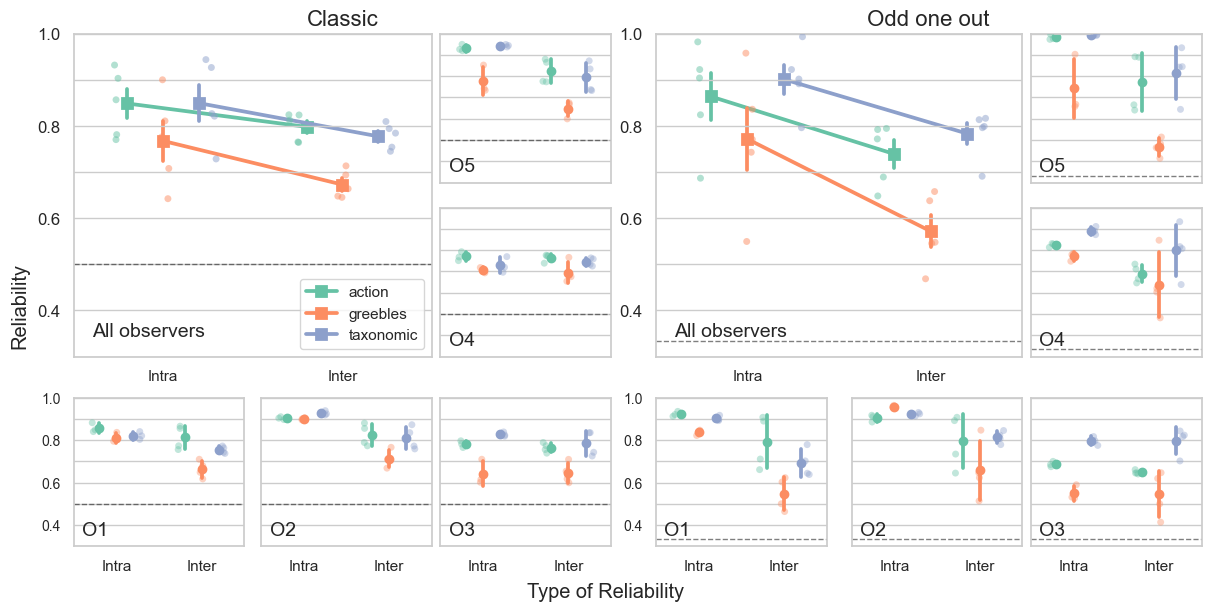

In [21]:
plotdots = True
plotavg = True
hue_order = ['action', 'greebles', 'taxonomic']
tasks = ['classic', 'odd one out']

task_axes = {}  # all axes of each task, to centre its heading over them

## set up figure and subplot grid
fig = plt.figure(layout="constrained", figsize=(12, 6))

gs = GridSpec(3, 6, figure=fig)

for t in tasks:

    if t == 'classic':
        ax5 = fig.add_subplot(gs[0, 2])
        ax4 = fig.add_subplot(gs[1, 2])
        ax3 = fig.add_subplot(gs[2, 2])
        ax2 = fig.add_subplot(gs[2, 1])
        ax1 = fig.add_subplot(gs[2, 0])
        ax_mean = fig.add_subplot(gs[0:2, 0:2])
    
        plotmapping = {'O1': ax1,
                  'O2': ax2,
                  'O3': ax3,
                  'O4': ax4,
                  'O5': ax5
                  }
    elif t == 'odd one out':
        ax5 = fig.add_subplot(gs[0, 5])
        ax4 = fig.add_subplot(gs[1, 5])
        ax3 = fig.add_subplot(gs[2, 5])
        ax2 = fig.add_subplot(gs[2, 4])
        ax1 = fig.add_subplot(gs[2, 3])
        ax_mean = fig.add_subplot(gs[0:2, 3:5])
    
        plotmapping = {'O1': ax1,
                  'O2': ax2,
                  'O3': ax3,
                  'O4': ax4,
                  'O5': ax5
                  }
 

    
    # plot mean data
    if plotavg:
        sns.pointplot(data=df_mean[df_mean['Task']==t], x='Agreement_Type', y='Agreement', 
                      hue='ImageSet', palette=palette_imset,
                      hue_order = hue_order,
                      order = ['Intra', 'Inter'],
                      errorbar='se', marker="s", markersize=7, markeredgewidth=2,
                      ax=ax_mean, 
                      dodge=0.4,
                      zorder=0,
                     )

    if plotdots:
        sns.stripplot(data=df_mean[df_mean['Task']==t], 
                      x='Agreement_Type', y='Agreement', 
                      hue_order = hue_order,
                      hue='ImageSet', palette=palette_imset,
                      order = ['Intra', 'Inter'],
                      legend=False, alpha=0.5, size=5,
                      dodge=True,
                      ax=ax_mean)
    
    # plot individual observer data
    for obs, ax in plotmapping.items():
        if plotdots:
            sns.stripplot(data=df_combined[(df_combined['Reference Observer']==obs) & (df_combined['Task']==t)], 
                          x='Agreement_Type', y='Agreement', 
                          hue_order = hue_order,
                          hue='ImageSet', palette=palette_imset,
                          order = ['Intra', 'Inter'],
                          legend=False, alpha=0.4, size=5,
                          dodge=0.4,
                          ax=ax)
        if plotavg:
            sns.pointplot(data=df_combined[(df_combined['Reference Observer']==obs) & (df_combined['Task']==t)], 
                          x='Agreement_Type', y='Agreement', 
                          hue_order = hue_order,
                          hue='ImageSet', palette=palette_imset,
                          order = ['Intra', 'Inter'],
                          legend=False, markersize=5,
                          linestyles='', ci='sd', dodge=0.4,
                          ax=ax, 
                         )
    # set titles
    for obs, ax in plotmapping.items():
        #ax.set_title(obs)
        ax.annotate(obs, xy=(0.05, 0.05), xycoords='axes fraction',
                    xytext=(0.05, 0.05), textcoords='offset points',
                    ha="left", va="bottom", fontsize=14, 
                   )

    # heading of the task, centred over all of its panels below
    ax_mean.set_title(t.capitalize(), fontsize=16)
    task_axes[t] = (ax_mean, [ax_mean, ax1, ax2, ax3, ax4, ax5])
    ax_mean.annotate('All observers', xy=(0.05, 0.05), xycoords='axes fraction',
                    xytext=(0.05, 0.05), textcoords='offset points',
                    ha="left", va="bottom", fontsize=14, 
                   )

    
    # set axes style for all observer
    #if t=='classic':
    for ax in [ax1, ax2, ax3, ax4, ax5]:
        ax.set_ylim(yrange)
        ax.set_ylabel('')
        ax.set_xlabel('')
        ax.set_yticks(yticks)
        ax.set_yticklabels(ylabels, fontsize=10)

    
    ax_mean.set_ylabel('')
    ax_mean.set_xlabel('')
    
    #if t=='classic':
    ax_mean.set_ylim(yrange)
    ax_mean.set_yticks(yticks)
    #ax_mean.set_yticklabels([]) 
    ax_mean.set_yticklabels(ylabels, fontsize=12)
    # one legend for the figure, in the classic panel
    if t == 'classic':
        ax_mean.legend(loc='lower right')
    else:
        ax_mean.get_legend().remove()
       

    ax4.set_xticklabels([])
    ax5.set_xticklabels([])
    ax2.set_yticklabels([])
    ax3.set_yticklabels([])
    ax4.set_yticklabels([])
    ax5.set_yticklabels([])   


    # chance level: agreement expected between two random responders,
    # one of two choices in the classic task, one of three in odd one out
    chance = 0.5 if t == 'classic' else 1/3
    for ax in [ax_mean, ax1, ax2, ax3, ax4, ax5]:
        ax.axhline(chance, color='k', linestyle='dashed', linewidth=1, alpha=0.5, zorder=1)


fig.supxlabel('Type of Reliability')
fig.supylabel('Reliability')

# centre each heading over the panels of its task, once the layout is done
fig.canvas.draw()
for ax_mean, axes in task_axes.values():
    boxes = [ax.get_position() for ax in axes]
    centre = (min(b.x0 for b in boxes) + max(b.x1 for b in boxes)) / 2
    top = ax_mean.get_position()
    ax_mean.title.set_x((centre - top.x0) / top.width)

fig.savefig("../plots/Comparisong_Intra_vs_Inter/raw_reliability_all_edited.pdf")

## same as before but scaled reliability

In [22]:
yrange = [0.0, 1]
yticks = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
ylabels = ['0.0', '', '0.2', '', '0.4', '', '0.6', '', '0.8', '', '1.0']

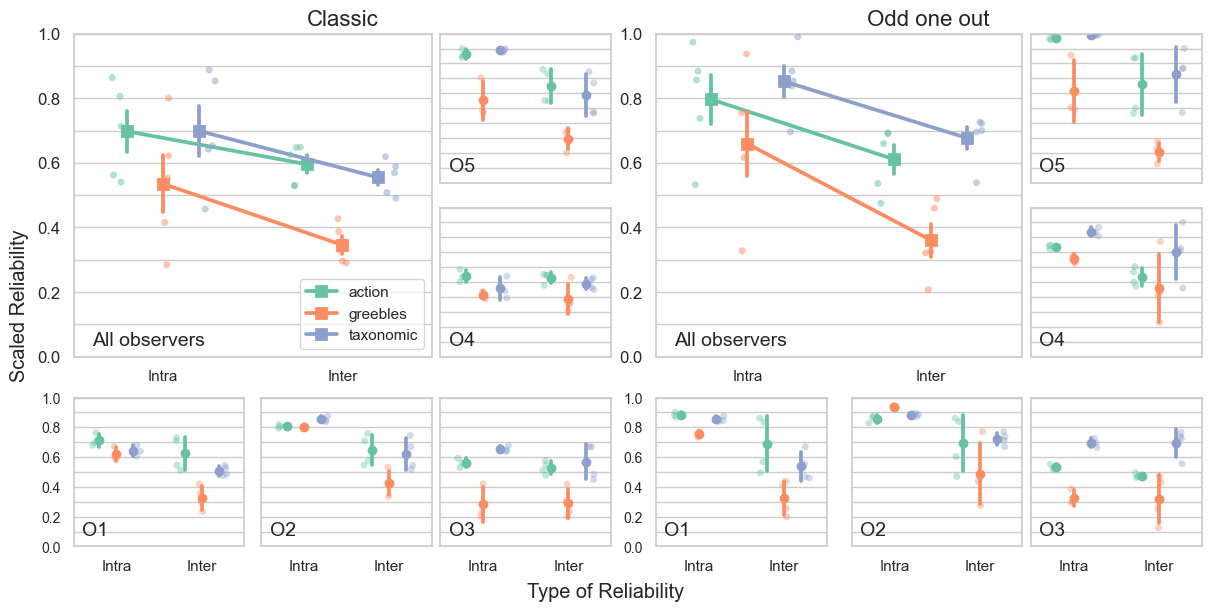

In [23]:
plotdots = True
plotavg = True
hue_order = ['action', 'greebles', 'taxonomic']
tasks = ['classic', 'odd one out']

task_axes = {}  # all axes of each task, to centre its heading over them

## set up figure and subplot grid
fig = plt.figure(layout="constrained", figsize=(12, 6))

gs = GridSpec(3, 6, figure=fig)

for t in tasks:

    if t == 'classic':
        ax5 = fig.add_subplot(gs[0, 2])
        ax4 = fig.add_subplot(gs[1, 2])
        ax3 = fig.add_subplot(gs[2, 2])
        ax2 = fig.add_subplot(gs[2, 1])
        ax1 = fig.add_subplot(gs[2, 0])
        ax_mean = fig.add_subplot(gs[0:2, 0:2])
    
        plotmapping = {'O1': ax1,
                  'O2': ax2,
                  'O3': ax3,
                  'O4': ax4,
                  'O5': ax5
                  }
    elif t == 'odd one out':
        ax5 = fig.add_subplot(gs[0, 5])
        ax4 = fig.add_subplot(gs[1, 5])
        ax3 = fig.add_subplot(gs[2, 5])
        ax2 = fig.add_subplot(gs[2, 4])
        ax1 = fig.add_subplot(gs[2, 3])
        ax_mean = fig.add_subplot(gs[0:2, 3:5])
    
        plotmapping = {'O1': ax1,
                  'O2': ax2,
                  'O3': ax3,
                  'O4': ax4,
                  'O5': ax5
                  }
 

    
    # plot mean data
    if plotavg:
        sns.pointplot(data=df_mean[df_mean['Task']==t], x='Agreement_Type', y='Scaled Agreement', 
                      hue='ImageSet', palette=palette_imset,
                      hue_order = hue_order,
                      order = ['Intra', 'Inter'],
                      errorbar='se', marker="s", markersize=7, markeredgewidth=2,
                      ax=ax_mean, 
                      dodge=0.4,
                      zorder=1,
                     )

    if plotdots:
        sns.stripplot(data=df_mean[df_mean['Task']==t], 
                      x='Agreement_Type', y='Scaled Agreement', 
                      hue_order = hue_order,
                      hue='ImageSet', palette=palette_imset,
                      order = ['Intra', 'Inter'],
                      legend=False, alpha=0.5, size=5,
                      dodge=True,
                      ax=ax_mean)
    
    # plot individual observer data
    for obs, ax in plotmapping.items():
        if plotdots:
            sns.stripplot(data=df_combined[(df_combined['Reference Observer']==obs) & (df_combined['Task']==t)], 
                          x='Agreement_Type', y='Scaled Agreement', 
                          hue_order = hue_order,
                          hue='ImageSet', palette=palette_imset,
                          order = ['Intra', 'Inter'],
                          legend=False, alpha=0.4, size=5,
                          dodge=0.4,
                          ax=ax)
        if plotavg:
            sns.pointplot(data=df_combined[(df_combined['Reference Observer']==obs) & (df_combined['Task']==t)], 
                          x='Agreement_Type', y='Scaled Agreement', 
                          hue_order = hue_order,
                          hue='ImageSet', palette=palette_imset,
                          order = ['Intra', 'Inter'],
                          legend=False, markersize=5,
                          linestyles='', ci='sd', dodge=0.4,
                          ax=ax, 
                         )
    # set titles
    for obs, ax in plotmapping.items():
        #ax.set_title(obs)
        ax.annotate(obs, xy=(0.05, 0.05), xycoords='axes fraction',
                    xytext=(0.05, 0.05), textcoords='offset points',
                    ha="left", va="bottom", fontsize=14, 
                   )

    # heading of the task, centred over all of its panels below
    ax_mean.set_title(t.capitalize(), fontsize=16)
    task_axes[t] = (ax_mean, [ax_mean, ax1, ax2, ax3, ax4, ax5])
    # centred between the grid lines at 0 and 0.1
    ax_mean.annotate('All observers', xy=(0.05, 0.05), xycoords=('axes fraction', 'data'),
                    ha="left", va="center", fontsize=14,
                   )

    
    # set axes style for all observer
    #if t=='classic':
    for ax in [ax1, ax2, ax3, ax4, ax5]:
        ax.set_ylim(yrange)
        ax.set_ylabel('')
        ax.set_xlabel('')
        ax.set_yticks(yticks)
        ax.set_yticklabels(ylabels, fontsize=10)

    
    ax_mean.set_ylabel('')
    ax_mean.set_xlabel('')
    
    #if t=='classic':
    ax_mean.set_ylim(yrange)
    ax_mean.set_yticks(yticks)
    #ax_mean.set_yticklabels([]) 
    ax_mean.set_yticklabels(ylabels, fontsize=12)
    # one legend for the figure, in the classic panel
    if t == 'classic':
        ax_mean.legend(loc='lower right')
    else:
        ax_mean.get_legend().remove()
       

    ax4.set_xticklabels([])
    ax5.set_xticklabels([])
    ax2.set_yticklabels([])
    ax3.set_yticklabels([])
    ax4.set_yticklabels([])
    ax5.set_yticklabels([])   


fig.supxlabel('Type of Reliability')
fig.supylabel('Scaled Reliability')

# centre each heading over the panels of its task, once the layout is done
fig.canvas.draw()
for ax_mean, axes in task_axes.values():
    boxes = [ax.get_position() for ax in axes]
    centre = (min(b.x0 for b in boxes) + max(b.x1 for b in boxes)) / 2
    top = ax_mean.get_position()
    ax_mean.title.set_x((centre - top.x0) / top.width)

fig.savefig("../plots/Comparisong_Intra_vs_Inter/scaled_reliability_all_edited.pdf")

## Fig. Reliability Intra/Inter per task (color) / collapsing image set

In [24]:
yrange = [0.3, 1]
yticks = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
ylabels = ['', '0.4', '', '0.6', '', '0.8', '', '1.0']

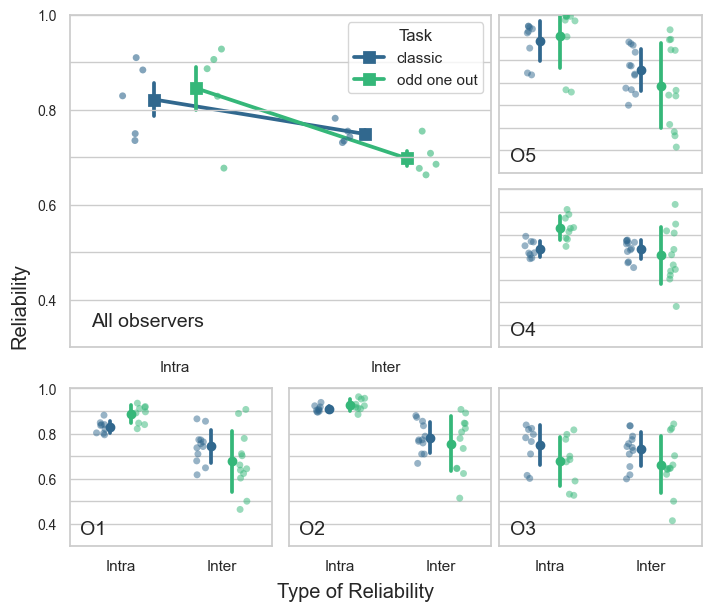

In [25]:
# Get unique observers
observers = df_combined_with_mean_img["Reference Observer"].unique()

# Prepare layout: 1 large plot on top (the last one), 5 smaller plots below
fig = plt.figure(layout="constrained", figsize=(7, 6))

gs = GridSpec(3, 3, figure=fig)

ax5 = fig.add_subplot(gs[0, 2])
ax4 = fig.add_subplot(gs[1, 2])
ax3 = fig.add_subplot(gs[2, 2])
ax2 = fig.add_subplot(gs[2, 1])
ax1 = fig.add_subplot(gs[2, 0])     

plotmapping = {'O1': ax1,
          'O2': ax2,
          'O3': ax3,
          'O4': ax4,
          'O5': ax5
          }


# Plot the large subplot (last observer)
#ax_big       = fig.add_subplot(gs[1:4])  # Top row, span all 5 columns
ax_big  = fig.add_subplot(gs[0:2, 0:2])
observer_big = observers[-1]
df_big       = df_combined_with_mean_img[df_combined_with_mean_img["Reference Observer"] == observer_big]

sns.stripplot(data=df_big, x='Agreement_Type', y='Agreement', hue='Task', 
              order=['Intra', 'Inter'], alpha=0.6, palette=palette_task, ax=ax_big, legend=False,
              dodge = 0.2, size=5)
sns.pointplot(data=df_big, x='Agreement_Type', y='Agreement', hue='Task',
              order=['Intra', 'Inter'], errorbar='se', markers='s', markersize=7, 
              #linestyles='none',
               markeredgewidth=2, dodge=0.2, ax=ax_big, palette=palette_task, legend=True, zorder=0)


        

ax_big.set_ylabel('')
ax_big.set_xlabel('')
ax_big.set_ylim(yrange)
ax_big.set_yticks(yticks)
ax_big.set_yticklabels(ylabels, fontsize=10)
ax_big.annotate("All observers", xy=(0.05, 0.05), xycoords='axes fraction',
        xytext=(0.05, 0.05), textcoords='offset points',
        ha="left", va="bottom", fontsize=14, 
       )

# Plot the small subplots
for i, observer in enumerate(observers[:-1]):  # First 5 observers
    ax = plotmapping[observer]
    
    df_small = df_combined_with_mean_img[df_combined_with_mean_img["Reference Observer"] == observer]

    sns.stripplot(data=df_small, x='Agreement_Type', y='Agreement', hue='Task',
                  order=['Intra', 'Inter'], alpha=0.5, palette=palette_task, ax=ax,
                  dodge=0.2, legend=False, size=5)
    sns.pointplot(data=df_small, x='Agreement_Type', y='Agreement', hue='Task',
                  order=['Intra', 'Inter'], errorbar='sd', markersize=5, linestyles='none',
                  dodge=0.2, ax=ax, palette=palette_task,
                  legend=False
                 )


                          
    #ax.set_title(observer)
    ax.set_ylim(yrange)
    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.set_yticks(yticks)
    ax.set_yticklabels(ylabels, fontsize=10)

    ax.annotate(observer, xy=(0.05, 0.05), xycoords='axes fraction',
            xytext=(0.05, 0.05), textcoords='offset points',
            ha="left", va="bottom", fontsize=14, 
           )

ax4.set_xticklabels([])
ax5.set_xticklabels([])
ax2.set_yticklabels([])
ax3.set_yticklabels([])
ax4.set_yticklabels([])
ax5.set_yticklabels([])   
        
fig.supxlabel('Type of Reliability')
fig.supylabel('Reliability')

# Shared legend outside
# handles, labels = ax_big.get_legend_handles_labels()
# fig.legend(handles, labels, loc='upper center', ncol=2)

#plt.tight_layout(rect=[0, 0.05, 1, 1])  # Leave space for legend
plt.savefig("../plots/Comparisong_Intra_vs_Inter/reliability_only_task.pdf")

## same as before but scaled reliability

In [26]:
yrange = [0.0, 1]
yticks = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
ylabels = ['0.0', '', '0.2', '', '0.4', '', '0.6', '', '0.8', '', '1.0']

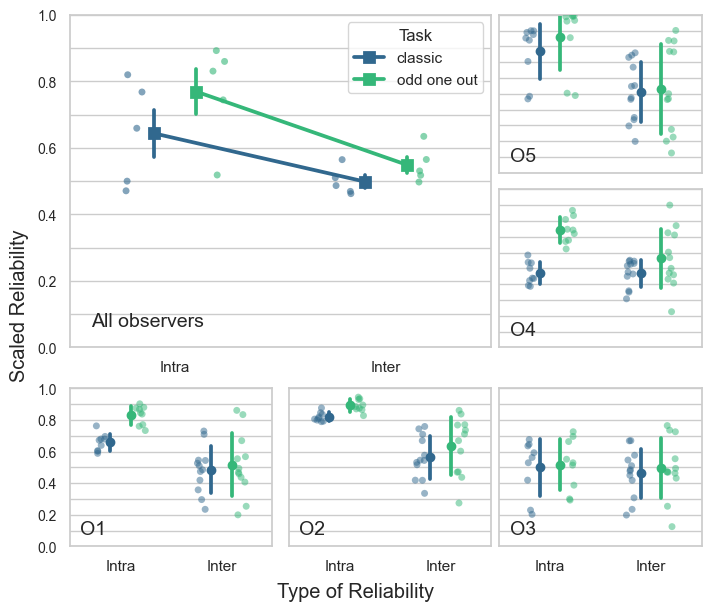

In [27]:
# Get unique observers
observers = df_combined_with_mean_img["Reference Observer"].unique()

# Prepare layout: 1 large plot on top (the last one), 5 smaller plots below
fig = plt.figure(layout="constrained", figsize=(7, 6))

gs = GridSpec(3, 3, figure=fig)

ax5 = fig.add_subplot(gs[0, 2])
ax4 = fig.add_subplot(gs[1, 2])
ax3 = fig.add_subplot(gs[2, 2])
ax2 = fig.add_subplot(gs[2, 1])
ax1 = fig.add_subplot(gs[2, 0])     

plotmapping = {'O1': ax1,
          'O2': ax2,
          'O3': ax3,
          'O4': ax4,
          'O5': ax5
          }

# Plot the large subplot (last observer)
#ax_big       = fig.add_subplot(gs[1:4])  # Top row, span all 5 columns
ax_big  = fig.add_subplot(gs[0:2, 0:2])
observer_big = observers[-1]
df_big       = df_combined_with_mean_img[df_combined_with_mean_img["Reference Observer"] == observer_big]

sns.stripplot(data=df_big, x='Agreement_Type', y='Scaled Agreement', hue='Task', 
              order=['Intra', 'Inter'], alpha=0.6, palette=palette_task, ax=ax_big, legend=False,
              dodge = 0.2, size=5)
sns.pointplot(data=df_big, x='Agreement_Type', y='Scaled Agreement', hue='Task',
              order=['Intra', 'Inter'], errorbar='se', markers='s', markersize=7, 
              #linestyles='none',
               markeredgewidth=2, dodge=0.2, ax=ax_big, palette=palette_task, legend=True, zorder=1)


ax_big.set_ylabel('')
ax_big.set_xlabel('')
ax_big.set_ylim(yrange)
ax_big.set_yticks(yticks)
ax_big.set_yticklabels(ylabels, fontsize=10)
ax_big.annotate("All observers", xy=(0.05, 0.05), xycoords='axes fraction',
        xytext=(0.05, 0.05), textcoords='offset points',
        ha="left", va="bottom", fontsize=14, 
       )

# Plot the small subplots
for i, observer in enumerate(observers[:-1]):  # First 5 observers
    ax = plotmapping[observer]
    
    df_small = df_combined_with_mean_img[df_combined_with_mean_img["Reference Observer"] == observer]

    sns.stripplot(data=df_small, x='Agreement_Type', y='Scaled Agreement', hue='Task',
                  order=['Intra', 'Inter'], alpha=0.5, palette=palette_task, ax=ax,
                  dodge=0.2, legend=False, size=5)
    sns.pointplot(data=df_small, x='Agreement_Type', y='Scaled Agreement', hue='Task',
                  order=['Intra', 'Inter'], errorbar='sd', markersize=5, linestyles='none',
                  dodge=0.2, ax=ax, palette=palette_task,
                  legend=False
                 )
                          
    #ax.set_title(observer)
    ax.set_ylim(yrange)
    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.set_yticks(yticks)
    ax.set_yticklabels(ylabels, fontsize=10)

    ax.annotate(observer, xy=(0.05, 0.05), xycoords='axes fraction',
            xytext=(0.05, 0.05), textcoords='offset points',
            ha="left", va="bottom", fontsize=14, 
           )

ax4.set_xticklabels([])
ax5.set_xticklabels([])
ax2.set_yticklabels([])
ax3.set_yticklabels([])
ax4.set_yticklabels([])
ax5.set_yticklabels([])   
        
fig.supxlabel('Type of Reliability')
fig.supylabel('Scaled Reliability')

# Shared legend outside
# handles, labels = ax_big.get_legend_handles_labels()
# fig.legend(handles, labels, loc='upper center', ncol=2)

#plt.tight_layout(rect=[0, 0.05, 1, 1])  # Leave space for legend
plt.savefig("../plots/Comparisong_Intra_vs_Inter/scaled_reliability_only_task.pdf")

## Drop in reliability from intra- to inter-observer (Table 2, Supplementary Figure S5)

For each reference observer, task and image set: the mean reliability of the observer with
themselves (intra, over the three sessions) and with the other four observers (inter, over the
four comparisons), for the raw and for the scaled reliability. The drop is computed in two ways:

- `drop_points`: inter minus intra, in percentage points;
- `drop_percent`: the same difference relative to intra, in percent.

Table 2 shows `drop_percent` of the raw (top) and scaled (bottom) reliability, averaged over the three
image sets. Figure S5 shows `drop_percent` of the scaled reliability. Since these are ratios, their means
are not the differences between the mean intra- and inter-observer reliabilities of Table 1.


In [28]:
RELIABILITY_LABELS = {'Agreement': 'Raw', 'Scaled Agreement': 'Scaled'}

drops_by_measure = []
for measure, label in RELIABILITY_LABELS.items():
    by_condition = df_combined.groupby(
        ['Task', 'ImageSet', 'Agreement_Type', 'Reference Observer'], as_index=False)[measure].mean()
    measure_drops = by_condition.pivot_table(index=['Task', 'ImageSet', 'Reference Observer'],
                                             columns='Agreement_Type', values=measure).reset_index()
    measure_drops['drop_points'] = (measure_drops['Inter'] - measure_drops['Intra']) * 100
    measure_drops['drop_percent'] = (measure_drops['Inter'] - measure_drops['Intra']) / measure_drops['Intra'] * 100
    measure_drops['reliability'] = label
    drops_by_measure.append(measure_drops)
drops_all = pd.concat(drops_by_measure, ignore_index=True)

# Figure S5 shows the drop of the scaled reliability
drops = drops_all[drops_all.reliability == 'Scaled']
drops_all


Agreement_Type,Task,ImageSet,Reference Observer,Inter,Intra,drop_points,drop_percent,reliability
0,classic,action,O1,0.812269,0.856667,-4.439746,-5.182583,Raw
1,classic,action,O2,0.824137,0.903151,-7.901403,-8.748704,Raw
2,classic,action,O3,0.764148,0.781111,-1.696263,-2.171602,Raw
3,classic,action,O4,0.765244,0.770276,-0.503195,-0.653267,Raw
4,classic,action,O5,0.823734,0.931961,-10.822740,-11.612865,Raw
5,classic,greebles,O1,0.663753,0.810803,-14.705004,-18.136353,Raw
6,classic,greebles,O2,0.713375,0.900000,-18.662493,-20.736103,Raw
7,classic,greebles,O3,0.645098,0.642222,0.287540,0.447727,Raw
8,classic,greebles,O4,0.693599,0.707778,-1.417839,-2.003226,Raw
9,classic,greebles,O5,0.647801,0.776230,-12.842957,-16.545293,Raw


In [29]:
# Table 2: drop relative to intra, in percent, per observer and task, averaged over image sets,
# raw reliability on top and scaled reliability below
table_drops = drops_all.groupby(['reliability', 'Reference Observer', 'Task'])['drop_percent'].mean().unstack('Task')
table_drops = table_drops.loc[list(RELIABILITY_LABELS.values())]
print(table_drops.round(1))
print()
print(table_drops.to_latex(float_format='%.1f'))


Task                            classic  odd one out
reliability Reference Observer                      
Raw         O1                    -10.5        -24.0
            O2                    -14.0        -18.4
            O3                     -2.3         -2.1
            O4                     -0.1        -14.7
            O5                    -14.7        -25.4
Scaled      O1                    -26.9        -38.6
            O2                    -31.2        -28.4
            O3                     -5.7         -4.2
            O4                     -0.5        -24.6
            O5                    -35.1        -41.8

\begin{tabular}{llrr}
\toprule
 & Task & classic & odd one out \\
reliability & Reference Observer &  &  \\
\midrule
\multirow[t]{5}{*}{Raw} & O1 & -10.5 & -24.0 \\
 & O2 & -14.0 & -18.4 \\
 & O3 & -2.3 & -2.1 \\
 & O4 & -0.1 & -14.7 \\
 & O5 & -14.7 & -25.4 \\
\cline{1-4}
\multirow[t]{5}{*}{Scaled} & O1 & -26.9 & -38.6 \\
 & O2 & -31.2 & -28.4 \\
 & O3 & -5.7 

In [30]:
# quoted in the text: means over observers and image sets, and the range over the per-observer values of Table 2
print(drops_all.groupby(['reliability', 'Task'])['drop_percent'].mean().unstack('Task').round(1))
print()
print(table_drops.abs().groupby('reliability').agg(['min', 'max']).round(1))


Task         classic  odd one out
reliability                      
Raw             -8.3        -16.9
Scaled         -19.9        -27.5

Task        classic       odd one out      
                min   max         min   max
reliability                                
Raw             0.1  14.7         2.1  25.4
Scaled          0.5  35.1         4.2  41.8


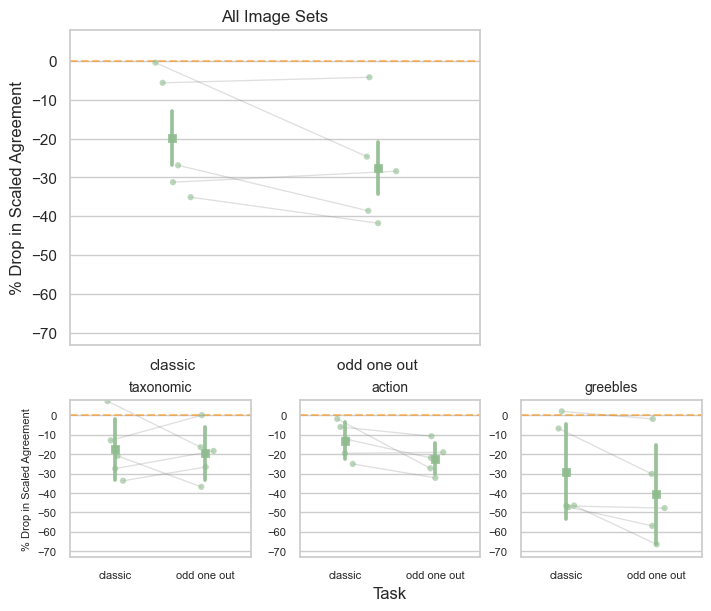

In [31]:
# Supplementary Figure S5: drop in percent per image set, plus one panel with the mean over image sets per observer
all_image_sets_label = 'All Image Sets'
drops_all_image_sets = drops.groupby(['Task', 'Reference Observer'], as_index=False)['drop_percent'].mean()
drops_all_image_sets['ImageSet'] = all_image_sets_label
drops_to_plot = pd.concat([drops[['Task', 'ImageSet', 'Reference Observer', 'drop_percent']], drops_all_image_sets],
                          ignore_index=True)

task_order = ['classic', 'odd one out']
task_position = {t: i for i, t in enumerate(task_order)}
y_lims = (drops_to_plot.drop_percent.min() * 1.1, drops_to_plot.drop_percent.max() * 1.1)


def plot_observers_with_jitter(ax, data, jitter_width=0.1):
    for observer, subdf in data.groupby('Reference Observer'):
        subdf = subdf.assign(_task_order=subdf['Task'].map(task_position)).sort_values('_task_order')
        # one generator per observer, so the jitter of an observer is the same in every panel and every run
        rng = np.random.default_rng(SEED + obs_names.index(observer))
        x_base = subdf['_task_order'].values.astype(float)
        x_jitter = x_base + rng.uniform(-jitter_width, jitter_width, size=x_base.shape)
        y_vals = subdf['drop_percent'].values
        ax.plot(x_jitter, y_vals, color='gray', alpha=0.25, linewidth=0.95, zorder=1)
        ax.scatter(x_jitter, y_vals, alpha=0.6, s=20, zorder=2, edgecolor='none', marker='o', color='darkseagreen')

    # mean with SD over observers per image set, SE in the panel of all image sets
    error = 'se' if data['ImageSet'].iloc[0] == all_image_sets_label else 'sd'
    sns.pointplot(data=data, x='Task', y='drop_percent', order=task_order, dodge=False,
                  color='darkseagreen', alpha=0.9, errorbar=error, marker='s', markersize=4,
                  markeredgewidth=2, linestyles='none', zorder=3, ax=ax)
    ax.axhline(0, linestyle='--', color='darkorange', alpha=0.5, zorder=1.5)
    ax.set_xticks(list(task_position.values()))
    ax.set_xticklabels(task_order)
    ax.set_ylim(y_lims)
    ax.set_xlabel('')
    ax.set_ylabel('')


# layout of Figure 2: one large panel for the mean over image sets, one small panel per image set below
fig = plt.figure(layout='constrained', figsize=(7, 6))
gs = GridSpec(3, 3, figure=fig)
ax_big = fig.add_subplot(gs[0:2, 0:2])
plot_observers_with_jitter(ax_big, drops_to_plot[drops_to_plot.ImageSet == all_image_sets_label])
ax_big.set_title(all_image_sets_label)
ax_big.set_ylabel('% Drop in Scaled Agreement')

for column, image_set in enumerate(['taxonomic', 'action', 'greebles']):
    ax = fig.add_subplot(gs[2, column], sharey=ax_big)
    plot_observers_with_jitter(ax, drops_to_plot[drops_to_plot.ImageSet == image_set])
    ax.set_title(image_set, fontsize=10)
    ax.tick_params(labelsize=8)
    if column == 0:
        ax.set_ylabel('% Drop in Scaled Agreement', fontsize=8)
    if column == 1:
        ax.set_xlabel('Task')

fig.savefig('../plots/Comparisong_Intra_vs_Inter/percentage_difference_agreement_inter_minus_intra_all_imgsets_big.pdf')


## Two views of the same greeble (Supplementary Table S6)

Percentage of trials in which observers kept two views of the same greeble together: in the classic
task, the other view was chosen as more similar to the reference; in the odd-one-out task, the other
greeble was chosen as odd. See `greeble_views.py`. P1 is the same person as O5, so their data are
pooled under O5; P2 is reported on its own.

In [32]:
greebles_info = pd.read_csv(DATA_ROOT / 'resources/greebles_info.csv')
greeble_sessions = load_all()
greeble_sessions = greeble_sessions[greeble_sessions.image_set == 'greebles']
greeble_sessions['observer'] = greeble_sessions['observer'].replace({'P1': 'O5'})

views_rates = same_individual_rate(greeble_sessions, greebles_info['Individual'].values)
views_table = pd.Series({key: rate for key, (rate, n) in views_rates.items()}).unstack()
views_trials = pd.Series({key: n for key, (rate, n) in views_rates.items()}).unstack()
print('informative trials:')
print(views_trials)
print()
print(views_table.round(1).to_latex(float_format='%.1f'))

informative trials:
    classic  odd one out
O1      141          219
O2      141          219
O3      141          219
O4      132          219
O5      292          434
P2      198          287

\begin{tabular}{lrr}
\toprule
 & classic & odd one out \\
\midrule
O1 & 92.9 & 98.2 \\
O2 & 98.6 & 99.5 \\
O3 & 80.9 & 79.0 \\
O4 & 88.6 & 92.7 \\
O5 & 99.3 & 99.1 \\
P2 & 98.5 & 97.9 \\
\bottomrule
\end{tabular}

